# NovaRetail 360 · Laboratorio 3 · Análisis exploratorio con Python
**Inteligencia de Negocios · Ing. Nancy Gélvez Garcia PhD. · UDistrital**

**Equipo:** Juan Felipe Rodríguez Galindo (20261595004) · Carlos Stiven Mora Hoyos (20261595003)

**Pregunta de la clase:** ¿qué está reduciendo los ingresos netos de NovaRetail 360: los descuentos, las devoluciones o la composición de las ventas?

**Base usada:** la del equipo de los laboratorios 1 y 2 (`novaretail_estrella.db`, 1.193 ventas). La referencia de la clase tiene 1.192: la diferencia es la venta V00410, que nuestra bitácora del laboratorio 1 conservó imputando el precio de lista (regla R6).

Se ejecuta en local con el entorno `.venv` de esta carpeta (kernel de Python con pandas y matplotlib). Ejecute las celdas en orden (Mayús + Enter): la primera toma la base de `../base/novaretail_estrella.db`.

## 1. Cargar los datos (minutos 0 a 20)
Use la base SQLite de su equipo de la clase 1 (la que tiene las tablas del laboratorio 1 y la estrella).

**Para subirla a Colab:** ejecute la celda siguiente, haga clic en **Elegir archivos** y seleccione su archivo `.db`. Espere a que diga *100% done*.

In [1]:
# Subir la base de datos a Colab
try:
    from google.colab import files
    subida = files.upload()                # abre el selector de archivos
    RUTA_BASE = list(subida.keys())[0]     # nombre del archivo que subió
except ImportError:
    RUTA_BASE = '../base/novaretail_estrella.db'   # fuera de Colab: base del equipo en este repositorio
print('Base que se va a usar:', RUTA_BASE)

Base que se va a usar: ../base/novaretail_estrella.db


In [2]:
# Bibliotecas: pandas para tablas, sqlite3 para leer la base, matplotlib para gráficas
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')   # números con separador de miles

conexion = sqlite3.connect(RUTA_BASE)

# Leer las tablas del laboratorio 1 como DataFrames (tablas de pandas)
ventas       = pd.read_sql('SELECT * FROM ventas', conexion)
devoluciones = pd.read_sql('SELECT * FROM devoluciones', conexion)
clientes     = pd.read_sql('SELECT * FROM clientes', conexion)
productos    = pd.read_sql('SELECT * FROM productos', conexion)

print('ventas:', ventas.shape, '| devoluciones:', devoluciones.shape,
      '| clientes:', clientes.shape, '| productos:', productos.shape)

ventas: (1193, 10) | devoluciones: (70, 4) | clientes: (120, 4) | productos: (40, 4)


In [3]:
# Primeras filas de ventas: así se ve un DataFrame
ventas.head()

,id_venta,fecha,id_cliente,id_producto,canal,cantidad,precio_unitario,descuento,importe_bruto,importe_neto
0,V00001,2026-06-13,C0015,P002,Web,6,39700,0.00,"238,200.00","238,200.00"
1,V00002,2026-02-27,C0018,P007,Marketplace,6,76400,0.15,"458,400.00","389,640.00"
2,V00003,2026-01-23,C0076,P028,Web,1,230800,0.00,"230,800.00","230,800.00"
3,V00004,2026-02-25,C0030,P033,Marketplace,5,267600,0.00,"1,338,000.00","1,338,000.00"
4,V00005,2026-02-20,C0092,P035,Tienda,4,282200,0.00,"1,128,800.00","1,128,800.00"


In [4]:
# Tipos de cada columna: los números deben ser int64 o float64, no object (texto)
ventas.dtypes

id_venta               str
fecha                  str
id_cliente             str
id_producto            str
canal                  str
cantidad             int64
precio_unitario      int64
descuento          float64
importe_bruto      float64
importe_neto       float64
dtype: object

**Respuesta:** las columnas numéricas quedaron como número (`cantidad` y `precio_unitario` int64, `descuento` float64); solo los identificadores, la fecha y el canal son texto, así que se puede calcular sin convertir tipos.

## 2. Preparar y combinar (minutos 20 a 70)
### 2.1 Filtrar y seleccionar

In [5]:
# Seleccionar columnas y filtrar filas: ventas de la Tienda con descuento
con_descuento = ventas[(ventas['canal'] == 'Tienda') & (ventas['descuento'] > 0)]
con_descuento[['id_venta', 'fecha', 'cantidad', 'precio_unitario', 'descuento']].head()

,id_venta,fecha,cantidad,precio_unitario,descuento
5,V00006,2026-05-31,2,32400,0.15
9,V00010,2026-02-01,1,208800,0.10
12,V00013,2026-01-26,4,157300,0.15
13,V00014,2026-02-11,2,194000,0.15
15,V00016,2026-02-15,2,142600,0.05


In [6]:
print('Ventas de Tienda con descuento:', len(con_descuento))

Ventas de Tienda con descuento: 207


**Respuesta:** hay **207 ventas de Tienda con descuento**, de 404 ventas de Tienda (51 %). En toda la base, 586 de 1.193 ventas (49 %) van sin descuento y el resto se reparte en 5 % (191), 10 % (198) y 15 % (218).

### 2.2 Combinar ventas con devoluciones, clientes y productos
Primero se suman las devoluciones **por venta** (igual que en SQL), para no repetir importes al combinar.

In [7]:
devueltas_por_venta = devoluciones.groupby('id_venta', as_index=False)['cantidad_devuelta'].sum()

datos = (ventas
         .merge(devueltas_por_venta, on='id_venta', how='left')   # left: conserva todas las ventas
         .merge(clientes[['id_cliente', 'region', 'segmento']], on='id_cliente', how='left')
         .merge(productos[['id_producto', 'categoria']], on='id_producto', how='left'))

datos['cantidad_devuelta'] = datos['cantidad_devuelta'].fillna(0)   # sin devolución = 0
print(datos.shape)
datos.head()

(1193, 14)


,id_venta,fecha,id_cliente,id_producto,canal,cantidad,precio_unitario,descuento,importe_bruto,importe_neto,cantidad_devuelta,region,segmento,categoria
0,V00001,2026-06-13,C0015,P002,Web,6,39700,0.00,"238,200.00","238,200.00",0.00,Bogotá,Persona,Oficina
1,V00002,2026-02-27,C0018,P007,Marketplace,6,76400,0.15,"458,400.00","389,640.00",0.00,Barranquilla,Corporativo,Accesorios
2,V00003,2026-01-23,C0076,P028,Web,1,230800,0.00,"230,800.00","230,800.00",0.00,Medellín,Corporativo,Tecnología
3,V00004,2026-02-25,C0030,P033,Marketplace,5,267600,0.00,"1,338,000.00","1,338,000.00",0.00,Bogotá,Corporativo,Hogar
4,V00005,2026-02-20,C0092,P035,Tienda,4,282200,0.00,"1,128,800.00","1,128,800.00",0.00,Cali,Corporativo,Accesorios


**Respuesta:** el resultado tiene **1.193 filas, las mismas que `ventas`**: sumar las devoluciones por venta antes del `merge` evita duplicar filas, y el `how='left'` conserva las ventas sin devolución (quedan con 0).

### 2.3 Calcular las medidas
Del precio de lista a las ventas netas hay dos pérdidas: los **descuentos** y las **devoluciones**.

In [8]:
datos['importe_bruto']   = datos['cantidad'] * datos['precio_unitario']
datos['valor_descuento'] = datos['importe_bruto'] * datos['descuento']
datos['importe_neto']    = datos['importe_bruto'] - datos['valor_descuento']
datos['valor_devuelto']  = datos['cantidad_devuelta'] * datos['precio_unitario'] * (1 - datos['descuento'])
datos['ventas_netas']    = datos['importe_neto'] - datos['valor_devuelto']
datos['periodo']         = datos['fecha'].str[:7]                # 'aaaa-mm'

datos[['id_venta', 'importe_bruto', 'valor_descuento', 'valor_devuelto', 'ventas_netas']].head()

,id_venta,importe_bruto,valor_descuento,valor_devuelto,ventas_netas
0,V00001,238200,0.00,0.00,"238,200.00"
1,V00002,458400,"68,760.00",0.00,"389,640.00"
2,V00003,230800,0.00,0.00,"230,800.00"
3,V00004,1338000,0.00,0.00,"1,338,000.00"
4,V00005,1128800,0.00,0.00,"1,128,800.00"


### 2.4 Validar contra SQL
El total de ventas netas en Python debe ser **igual** al control C2 de la clase 1. Si no coincide, hay un error en la preparación.

In [9]:
total_python = datos['ventas_netas'].sum()
total_sql = pd.read_sql('SELECT SUM(ventas_netas) AS total FROM FactVentas', conexion)['total'][0]

print(f'Ventas netas en Python: ${total_python:,.0f}')
print(f'Ventas netas en SQL:    ${total_sql:,.0f}')
print('¿Coinciden?', round(total_python) == round(total_sql))

Ventas netas en Python: $669,412,345
Ventas netas en SQL:    $669,412,345
¿Coinciden? True


**Respuesta:** **sí coinciden**: $669.412.345 en Python y en SQL, igual al control C2 del laboratorio 2. La preparación en pandas reproduce el modelo estrella.

## 3. Análisis exploratorio (minutos 80 a 125)
### 3.1 Estadística descriptiva

In [10]:
datos[['cantidad', 'precio_unitario', 'descuento', 'ventas_netas']].describe()

,cantidad,precio_unitario,descuento,ventas_netas
count,"1,193.00","1,193.00","1,193.00","1,193.00"
mean,3.51,"176,164.54",0.05,"561,116.80"
std,1.69,"85,289.83",0.06,"426,824.92"
min,1.00,"32,400.00",0.00,0.00
25%,2.00,"98,500.00",0.00,"230,800.00"
50%,4.00,"172,000.00",0.05,"442,340.00"
75%,5.00,"252,800.00",0.10,"811,200.00"
max,6.00,"319,000.00",0.15,"1,914,000.00"


**Respuesta:** la venta típica es de 3,5 unidades y $561 mil netos (mediana $442 mil). Las ventas netas van de $0 (27 ventas devueltas completas) a $1,9 millones, y la media supera a la mediana: la distribución tiene cola a la derecha. El descuento promedio por venta es 5 %.

### 3.2 ¿Cuánto se pierde entre el importe bruto y las ventas netas?

In [11]:
bruto       = datos['importe_bruto'].sum()
descuentos  = datos['valor_descuento'].sum()
devuelto    = datos['valor_devuelto'].sum()
netas       = datos['ventas_netas'].sum()
perdida     = bruto - netas

resumen = pd.DataFrame({
    'concepto': ['Importe bruto', 'Descuentos', 'Devoluciones', 'Ventas netas'],
    'valor':    [bruto, -descuentos, -devuelto, netas]})
print(resumen.to_string(index=False))
print(f'\nPérdida total: ${perdida:,.0f} ({perdida / bruto:.1%} del bruto)')
print(f'  Descuentos:   {descuentos / perdida:.1%} de la pérdida')
print(f'  Devoluciones: {devuelto / perdida:.1%} de la pérdida')

     concepto          valor
Importe bruto 736,912,100.00
   Descuentos -37,536,440.00
 Devoluciones -29,963,315.00
 Ventas netas 669,412,345.00

Pérdida total: $67,499,755 (9.2% del bruto)
  Descuentos:   55.6% de la pérdida
  Devoluciones: 44.4% de la pérdida


**Respuesta:** se pierden **$67,5 millones, el 9,2 % del bruto**. Los descuentos son el 55,6 % de la pérdida ($37,5 M) y las devoluciones el 44,4 % ($30,0 M): pesan parecido, con los descuentos un poco por delante.

### 3.3 ¿Dónde se pierde más? Agrupar por categoría, canal y región
`groupby` agrupa las filas y `agg` calcula los totales de cada grupo. Los porcentajes se calculan **después**, dividiendo totales (nunca promediando porcentajes).

In [12]:
def perdida_por(columna):
    t = datos.groupby(columna).agg(
        importe_bruto=('importe_bruto', 'sum'),
        descuentos=('valor_descuento', 'sum'),
        devoluciones=('valor_devuelto', 'sum'),
        ventas_netas=('ventas_netas', 'sum'),
        n_ventas=('id_venta', 'count'))
    t['pct_descuento']    = t['descuentos'] / t['importe_bruto'] * 100
    t['pct_devolucion']   = t['devoluciones'] / t['importe_bruto'] * 100
    t['pct_perdida']      = t['pct_descuento'] + t['pct_devolucion']
    t['participacion_vn'] = t['ventas_netas'] / t['ventas_netas'].sum() * 100
    return t.sort_values('pct_perdida', ascending=False)

perdida_por('categoria')

,importe_bruto,descuentos,devoluciones,ventas_netas,n_ventas,pct_descuento,pct_devolucion,pct_perdida,participacion_vn
categoria,,,,,,,,,
Tecnología,193922600,"8,574,260.00","11,588,770.00","173,759,570.00",292,4.42,5.98,10.40,25.96
Accesorios,192880000,"9,845,760.00","8,187,290.00","174,846,950.00",299,5.10,4.24,9.35,26.12
Oficina,180445700,"9,010,590.00","6,210,575.00","165,224,535.00",309,4.99,3.44,8.44,24.68
Hogar,169663800,"10,105,830.00","3,976,680.00","155,581,290.00",293,5.96,2.34,8.30,23.24


In [13]:
perdida_por('canal')

,importe_bruto,descuentos,devoluciones,ventas_netas,n_ventas,pct_descuento,pct_devolucion,pct_perdida,participacion_vn
canal,,,,,,,,,
Tienda,243435200,"12,787,160.00","12,386,930.00","218,261,110.00",404,5.25,5.09,10.34,32.60
Web,246453300,"12,059,755.00","9,491,185.00","224,902,360.00",378,4.89,3.85,8.74,33.60
Marketplace,247023600,"12,689,525.00","8,085,200.00","226,248,875.00",411,5.14,3.27,8.41,33.80


In [14]:
perdida_por('region')

,importe_bruto,descuentos,devoluciones,ventas_netas,n_ventas,pct_descuento,pct_devolucion,pct_perdida,participacion_vn
region,,,,,,,,,
Cali,156333100,"8,386,950.00","7,194,265.00","140,751,885.00",233,5.36,4.60,9.97,21.03
Bogotá,138022100,"6,797,000.00","6,399,615.00","124,825,485.00",226,4.92,4.64,9.56,18.65
Medellín,144199500,"6,622,065.00","7,118,925.00","130,458,510.00",231,4.59,4.94,9.53,19.49
Barranquilla,147714600,"7,878,610.00","5,365,390.00","134,470,600.00",258,5.33,3.63,8.97,20.09
Bucaramanga,150642800,"7,851,815.00","3,885,120.00","138,905,865.00",245,5.21,2.58,7.79,20.75


**Respuesta:** **por categoría**, Tecnología pierde más (10,4 %), y es por devoluciones (6,0 %, la más alta) más que por descuentos (4,4 %, el más bajo); Hogar es lo contrario (6,0 % de descuento, 2,3 % de devolución). **Por canal**, Tienda pierde más (10,3 %) por su devolución de 5,1 %. **Por región**, Cali pierde más (10,0 %) y Bucaramanga menos (7,8 %), y la diferencia viene casi toda de devoluciones. La participación en ventas netas es pareja en todos los cortes (23–26 % por categoría, 33–34 % por canal, 19–21 % por región).

### 3.4 ¿El descuento hace vender más unidades?

In [15]:
por_descuento = datos.groupby('descuento').agg(
    ventas=('id_venta', 'count'),
    cantidad_promedio=('cantidad', 'mean'))
print(por_descuento)
print('\nCorrelación entre descuento y cantidad:', round(datos['descuento'].corr(datos['cantidad']), 3))

           ventas  cantidad_promedio
descuento                           
0.00          586               3.47
0.05          191               3.62
0.10          198               3.62
0.15          218               3.43

Correlación entre descuento y cantidad: 0.004


**Respuesta:** **no**. Sin descuento se venden 3,47 unidades por venta y con 15 %, 3,43; con 5 % y 10 % son 3,62. La correlación es 0,004, prácticamente nula. Los descuentos reducen el ingreso sin aumentar el volumen.

### 3.5 Valores atípicos (regla del rango intercuartílico)
Un valor es atípico si está por encima de Q3 + 1,5 × (Q3 − Q1). **Atípico no significa error:** hay que revisar qué ventas son antes de decidir.

In [16]:
q1 = datos['ventas_netas'].quantile(0.25)
q3 = datos['ventas_netas'].quantile(0.75)
limite = q3 + 1.5 * (q3 - q1)
atipicas = datos[datos['ventas_netas'] > limite]

print(f'Q1 = ${q1:,.0f}   Q3 = ${q3:,.0f}   Límite = ${limite:,.0f}')
print('Ventas atípicas:', len(atipicas))
atipicas[['id_venta', 'id_producto', 'categoria', 'cantidad', 'precio_unitario', 'descuento', 'ventas_netas']].sort_values('ventas_netas', ascending=False).head(10)

Q1 = $230,800   Q3 = $811,200   Límite = $1,681,800
Ventas atípicas: 20


,id_venta,id_producto,categoria,cantidad,precio_unitario,descuento,ventas_netas
160,V00166,P040,Tecnología,6,319000,0.00,"1,914,000.00"
943,V00951,P040,Tecnología,6,319000,0.00,"1,914,000.00"
895,V00903,P040,Tecnología,6,319000,0.00,"1,914,000.00"
871,V00879,P039,Accesorios,6,311600,0.00,"1,869,600.00"
601,V00609,P038,Oficina,6,304300,0.00,"1,825,800.00"
18,V00019,P037,Hogar,6,297000,0.00,"1,782,000.00"
395,V00403,P037,Hogar,6,297000,0.00,"1,782,000.00"
1111,V01119,P037,Hogar,6,297000,0.00,"1,782,000.00"
206,V00213,P037,Hogar,6,297000,0.00,"1,782,000.00"
359,V00367,P039,Accesorios,6,311600,0.05,"1,776,120.00"


**Respuesta:** con Q1 = $230.800 y Q3 = $811.200, el límite es $1.681.800 y hay **20 ventas atípicas**. Todas son de 6 unidades de los productos más caros (P035 a P040, los seis más caros), 15 de ellas sin descuento. Son ventas reales, no errores: **no se eliminan**.

## 4. Visualizaciones (minutos 125 a 160)
Cada gráfica responde una pregunta. Escriba debajo de cada una, en una frase, qué muestra.

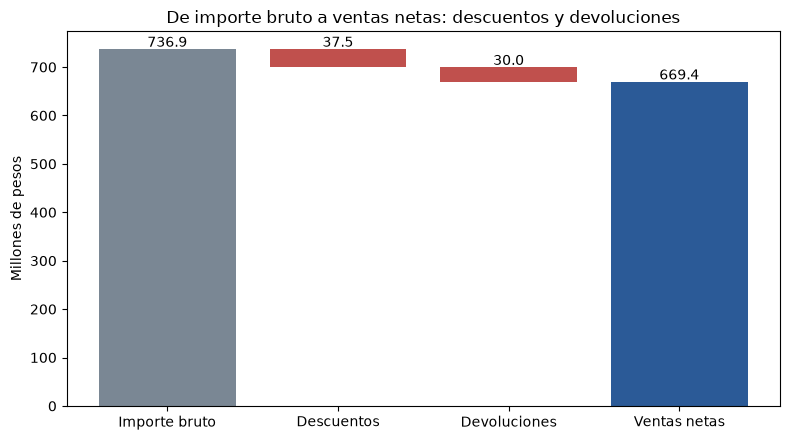

In [17]:
# 4.1 Del bruto a las ventas netas (millones de pesos)
pasos   = ['Importe bruto', 'Descuentos', 'Devoluciones', 'Ventas netas']
alturas = [bruto, descuentos, devuelto, netas]
bases   = [0, bruto - descuentos, bruto - descuentos - devuelto, 0]
colores = ['#7A8794', '#C0504D', '#C0504D', '#2B5A97']

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(pasos, [a / 1e6 for a in alturas], bottom=[b / 1e6 for b in bases], color=colores)
for i, a in enumerate(alturas):
    ax.text(i, (bases[i] + a) / 1e6 + 5, f'{a / 1e6:,.1f}', ha='center')
ax.set_ylabel('Millones de pesos')
ax.set_title('De importe bruto a ventas netas: descuentos y devoluciones')
plt.tight_layout()
plt.show()

**Qué muestra:** de $736,9 millones brutos se llega a $669,4 millones netos; los descuentos ($37,5 M) restan algo más que las devoluciones ($30,0 M).

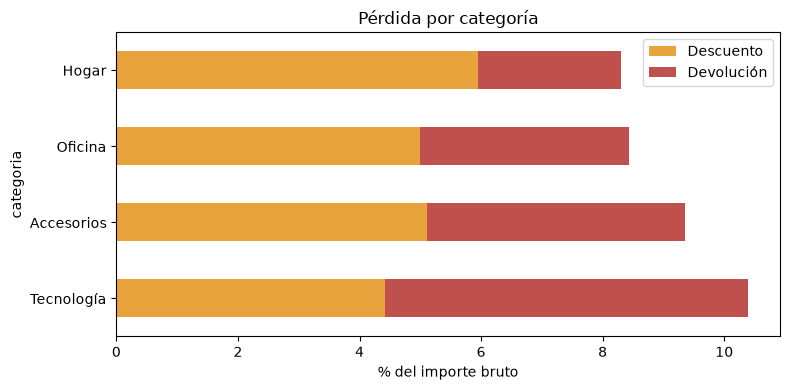

In [18]:
# 4.2 Pérdida por categoría: descuento y devolución como % del bruto
t = perdida_por('categoria')[['pct_descuento', 'pct_devolucion']]
ax = t.plot(kind='barh', stacked=True, figsize=(8, 4), color=['#E8A33D', '#C0504D'])
ax.set_xlabel('% del importe bruto')
ax.set_title('Pérdida por categoría')
ax.legend(['Descuento', 'Devolución'])
plt.tight_layout()
plt.show()

**Qué muestra:** Tecnología es la categoría que más pierde (10,4 % del bruto) y lo hace por devoluciones (6,0 %); Hogar es la de mayor descuento (6,0 %) pero la de menos devoluciones (2,3 %).

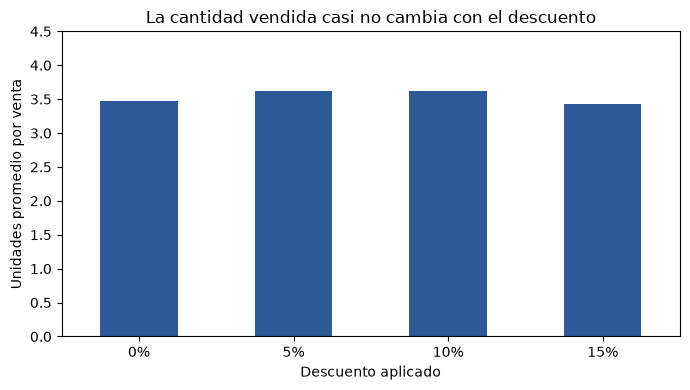

In [19]:
# 4.3 ¿Más descuento, más unidades? Cantidad promedio por nivel de descuento
ax = por_descuento['cantidad_promedio'].plot(kind='bar', figsize=(7, 4), color='#2B5A97')
ax.set_xticklabels([f'{d:.0%}' for d in por_descuento.index], rotation=0)
ax.set_xlabel('Descuento aplicado')
ax.set_ylabel('Unidades promedio por venta')
ax.set_ylim(0, 4.5)
ax.set_title('La cantidad vendida casi no cambia con el descuento')
plt.tight_layout()
plt.show()

**Qué muestra:** las unidades por venta se mantienen entre 3,4 y 3,6 con cualquier nivel de descuento (correlación 0,004): el descuento no está comprando volumen.

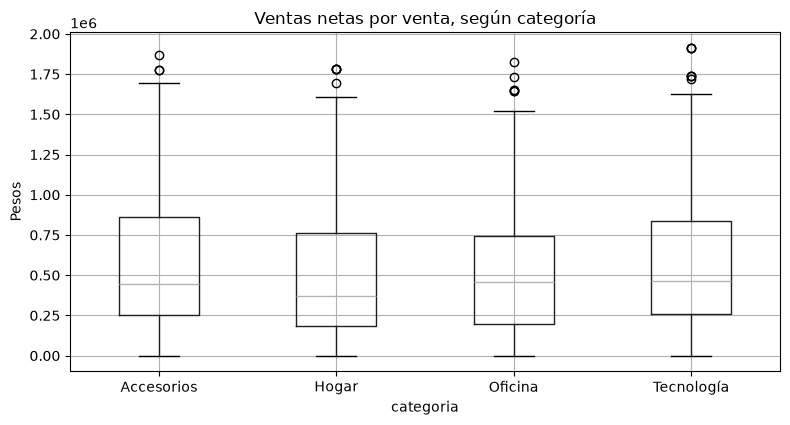

In [20]:
# 4.4 Distribución de las ventas netas por categoría (los puntos son atípicos)
datos.boxplot(column='ventas_netas', by='categoria', figsize=(8, 4.5))
plt.suptitle('')
plt.title('Ventas netas por venta, según categoría')
plt.ylabel('Pesos')
plt.tight_layout()
plt.show()

**Qué muestra:** las cuatro categorías tienen distribuciones parecidas (medianas entre $371 mil en Hogar y $463 mil en Tecnología); los puntos sobre las cajas son las 20 ventas atípicas, todas de 6 unidades de productos caros (P035 a P040).

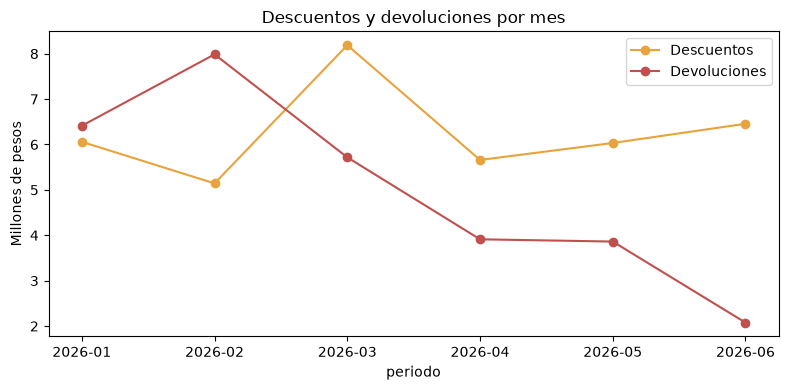

In [21]:
# 4.5 Devoluciones por mes de la venta original
mensual = datos.groupby('periodo')[['valor_descuento', 'valor_devuelto']].sum() / 1e6
ax = mensual.plot(marker='o', figsize=(8, 4), color=['#E8A33D', '#C0504D'])
ax.set_ylabel('Millones de pesos')
ax.set_title('Descuentos y devoluciones por mes')
ax.legend(['Descuentos', 'Devoluciones'])
plt.tight_layout()
plt.show()

**Qué muestra:** los descuentos se mantienen estables (5 a 8 M por mes), mientras las devoluciones caen de 8,0 M en febrero a 2,1 M en junio, en parte porque las ventas recientes aún no han tenido tiempo de devolverse.

## 5. Hallazgos y limitaciones · Cifras del equipo
Calculadas con nuestra base (1.193 ventas). Frente a la referencia (1.192), solo cambian el importe bruto y las ventas netas en +$579.200 por la venta V00410 (2 × P036 a $289.600, sin descuento ni devolución); los porcentajes coinciden al decimal. La validación 2.4 da **$669.412.345 en Python y en SQL** (control C2 del laboratorio 2).

**Hallazgo 1. Los descuentos pesan algo más que las devoluciones.** Entre el importe bruto ($736,9 millones) y las ventas netas ($669,4 millones) se pierden $67,5 millones (9,2 %). El 55,6 % son descuentos ($37,5 millones) y el 44,4 %, devoluciones ($30,0 millones). *Fuente: 3.2 y gráfica 4.1.*

**Hallazgo 2. Tecnología pierde más, y por devoluciones, no por descuentos.** Pierde el 10,4 % de su importe bruto: 6,0 % por devoluciones (la más alta) y 4,4 % por descuentos (la más baja). Hogar tiene el descuento más alto (6,0 %) pero las menores devoluciones (2,3 %). En canales, Tienda pierde más (10,3 %), con la devolución más alta (5,1 % frente a 3,3 % en Marketplace). Por región, Cali pierde más (10,0 %) y Bucaramanga menos (7,8 %), con una brecha que viene casi toda de devoluciones (4,6 % frente a 2,6 %). *Fuente: 3.3 y gráfica 4.2.*

**Hallazgo 3. Los descuentos no están comprando volumen.** La cantidad promedio por venta es casi igual sin descuento (3,47 unidades) y con 15 % (3,43); con 5 % y 10 % sube apenas a 3,62. La correlación es 0,004. *Fuente: 3.4 y gráfica 4.3.*

**Sobre la composición de las ventas:** las cuatro categorías aportan entre 23,2 % y 26,1 % de las ventas netas y los tres canales entre 32,6 % y 33,8 %. La mezcla está equilibrada y no explica la pérdida.

**Respuesta a la pregunta:** lo que reduce los ingresos netos son, en este orden, los **descuentos** (5,1 % del bruto) y las **devoluciones** (4,1 %), no la composición. Las devoluciones se concentran en Tecnología y en Tienda, y los descuentos no se traducen en más unidades: son las dos palancas que vale la pena revisar.

**Limitaciones:**
- Datos sintéticos de un solo semestre.
- Correlación no es causalidad: que el descuento no se asocie con más unidades no prueba que no sirva (podría atraer clientes nuevos, algo que estos datos no miden).
- Las devoluciones se asignan al mes de la venta: las de mayo y junio todavía pueden recibir devoluciones, por eso la tasa cae de 7,0 % en febrero a 1,6 % en junio (gráfica 4.5).
- Las 20 ventas atípicas son ventas legítimas de 6 unidades de productos caros, no errores: no se eliminan.
- 27 ventas quedan con ventas netas de $0 porque se devolvieron completas; se conservan porque son parte de la pérdida.